# Bài 6 (trang 26, mục IV.6) - Giảm số màu ảnh bằng K-Means

**Sinh viên:** Nguyễn Đức Vinh  
**MSSV:** 6451071087

Đọc ảnh, chuyển pixel RGB về [0,1], gom cụm màu với K=32, tái tạo ảnh và lưu kết quả.

> Chạy lần lượt các cell từ trên xuống dưới trong Google Colab. Mỗi notebook là một bài độc lập.

## 1. Thư viện và thông tin sinh viên

In [1]:
import os, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans

print("Nguyễn Đức Vinh - MSSV: 6451071087")

Nguyễn Đức Vinh - MSSV: 6451071087


## 2. Truy cập thư mục dữ liệu được chia sẻ và tìm ảnh

In [2]:
from pathlib import Path
import subprocess, sys, os

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/11cbz4e_1jq89C6tpzwVZsHPYIrackRXB?usp=sharing"
DATA_DIR = Path("/content/lab3_dataset")

# Nếu chạy trên Colab, gắn Google Drive trước; đồng thời tải thư mục được chia sẻ bằng gdown.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Không ở Google Colab hoặc không thể mount Drive; sẽ kiểm tra thư mục làm việc hiện tại.")

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "gdown"])
    import gdown

DATA_DIR.mkdir(parents=True, exist_ok=True)
try:
    gdown.download_folder(DRIVE_FOLDER_URL, output=str(DATA_DIR), quiet=False,
                          use_cookies=False, remaining_ok=True)
except Exception as exc:
    print("Không tải được thư mục Drive tự động:", exc)
    print("Hãy thêm shortcut thư mục chia sẻ vào MyDrive hoặc tải dữ liệu lên /content/lab3_dataset.")

# Tìm thêm trong MyDrive nếu thư mục dữ liệu đã được đồng bộ ở đó.
SEARCH_ROOTS = [DATA_DIR, Path("/content/drive/MyDrive")]

Mounted at /content/drive


Retrieving folder contents


Processing file 13qn-5-ccmFiPv4oPxcLxFol1KvRzk-L5 breast+cancer+wisconsin+diagnostic.zip
Processing file 1bsPcz8nZOMPcF3eVVs-EfmDRsqfjjUcC Mall_Customers.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=13qn-5-ccmFiPv4oPxcLxFol1KvRzk-L5
To: /content/lab3_dataset/breast+cancer+wisconsin+diagnostic.zip
100%|██████████| 51.3k/51.3k [00:00<00:00, 59.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1bsPcz8nZOMPcF3eVVs-EfmDRsqfjjUcC
To: /content/lab3_dataset/Mall_Customers.csv
100%|██████████| 3.98k/3.98k [00:00<00:00, 13.4MB/s]
Download completed


In [3]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_files = []
for root in SEARCH_ROOTS:
    if root.exists():
        image_files.extend([p for p in root.rglob("*")
                            if p.is_file() and p.suffix.lower() in image_extensions])
image_files = sorted(set(image_files))
print("Các ảnh tìm được:")
for p in image_files:
    print(p)

# Nếu thư mục có nhiều ảnh, sửa IMAGE_PATH thành đường dẫn ảnh mong muốn.
IMAGE_PATH = str(image_files[0]) if image_files else None
if IMAGE_PATH is None:
    raise FileNotFoundError("Không tìm thấy ảnh. Hãy tải ảnh vào /content/lab3_dataset hoặc đặt IMAGE_PATH thủ công.")
print("Ảnh được sử dụng:", IMAGE_PATH)

Nguyễn Đức Vinh - MSSV: 6451071087
Các ảnh tìm được:
/content/drive/MyDrive/BT-CSDL/20250210_165002.jpg
/content/drive/MyDrive/BT-CSDL/20250210_165012.jpg
/content/drive/MyDrive/BT-CSDL/20250210_165017.jpg
/content/drive/MyDrive/BT-CSDL/20250210_165027.jpg
/content/drive/MyDrive/BT-CSDL/20250210_165515.jpg
/content/drive/MyDrive/ViTHSD_GiaiDoan3/cnn_confusion_matrices.png
/content/drive/MyDrive/ViTHSD_GiaiDoan3/cnn_seed_stability.png
/content/drive/MyDrive/ViTHSD_GiaiDoan3/model_comparison_final.png
Ảnh được sử dụng: /content/drive/MyDrive/BT-CSDL/20250210_165002.jpg


## 3. Đọc ảnh và chuẩn bị dữ liệu RGB

In [4]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
image = Image.open(IMAGE_PATH).convert("RGB")
original_size = os.path.getsize(IMAGE_PATH)
original_array = np.asarray(image)
height, width, channels = original_array.shape
print("Kích thước ảnh (cao, rộng, sâu):", original_array.shape)
print("Dung lượng ảnh gốc:", original_size, "bytes")

# Giới hạn kích thước để giảm thời gian xử lý nhưng vẫn giữ tỷ lệ ảnh.
MAX_SIDE = 700
if max(height, width) > MAX_SIDE:
    scale = MAX_SIDE / max(height, width)
    new_size = (int(width * scale), int(height * scale))
    image = image.resize(new_size, Image.Resampling.LANCZOS)

image_array = np.asarray(image).astype("float32") / 255.0
h, w, c = image_array.shape
pixels = image_array.reshape(-1, 3)
print("Mảng pixel 2D:", pixels.shape)

Nguyễn Đức Vinh - MSSV: 6451071087
Kích thước ảnh (cao, rộng, sâu): (1864, 2250, 3)
Dung lượng ảnh gốc: 1400426 bytes
Mảng pixel 2D: (405300, 3)


## 4. Gom cụm màu với K-Means (32 màu)

In [5]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
N_COLORS = 32
# Nếu ảnh lớn, fit trên mẫu pixel để giảm chi phí; sau đó dự đoán nhãn cho mọi pixel.
MAX_TRAIN_PIXELS = 50000
rng = np.random.default_rng(42)
if len(pixels) > MAX_TRAIN_PIXELS:
    sampled_indices = rng.choice(len(pixels), size=MAX_TRAIN_PIXELS, replace=False)
    pixels_fit = pixels[sampled_indices]
else:
    pixels_fit = pixels

kmeans = KMeans(n_clusters=N_COLORS, random_state=42, n_init=3, max_iter=100)
kmeans.fit(pixels_fit)
pixel_labels = kmeans.predict(pixels)
compressed_pixels = kmeans.cluster_centers_[pixel_labels]
compressed_image = np.clip(compressed_pixels.reshape(h, w, 3) * 255, 0, 255).astype("uint8")
print("Số màu đại diện:", len(kmeans.cluster_centers_))

Nguyễn Đức Vinh - MSSV: 6451071087
Số màu đại diện: 32


## 5. Hiển thị và lưu ảnh kết quả

Nguyễn Đức Vinh - MSSV: 6451071087


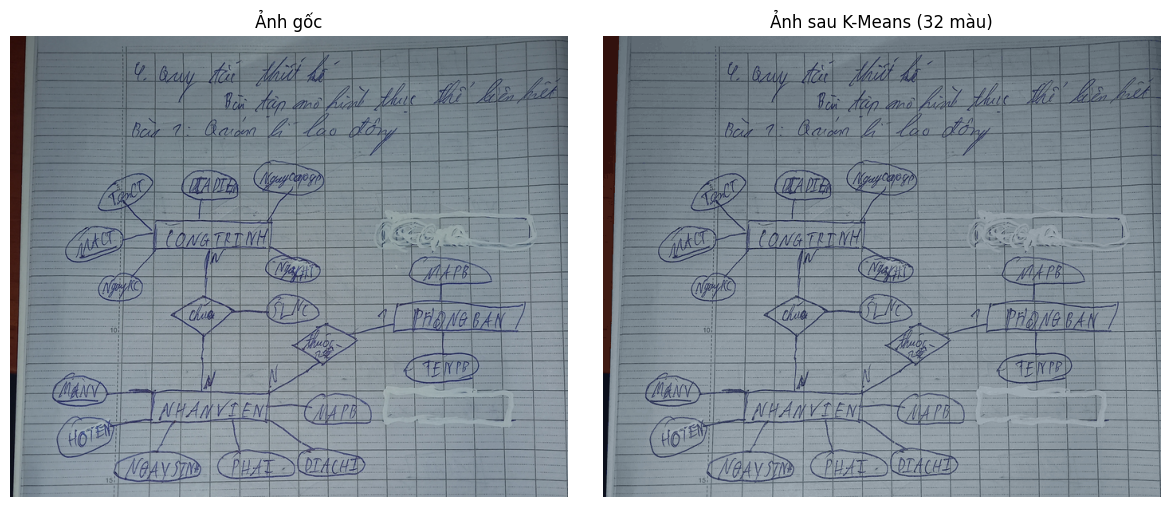

Đã lưu ảnh: /content/6451071087_LAB3_Bai6_image_32colors.png
Dung lượng ảnh kết quả: 416874 bytes
Tỷ lệ dung lượng kết quả/gốc: 0.2977
Lưu ý: PNG có thể lớn hơn JPG gốc tùy ảnh; K-Means giảm số màu, không bảo đảm mọi định dạng đầu ra đều có dung lượng nhỏ hơn.


In [6]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Ảnh gốc")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(compressed_image)
plt.title(f"Ảnh sau K-Means ({N_COLORS} màu)")
plt.axis("off")
plt.tight_layout()
plt.show()

OUTPUT_PATH = "/content/6451071087_LAB3_Bai6_image_32colors.png"
Image.fromarray(compressed_image).save(OUTPUT_PATH, optimize=True)
compressed_size = os.path.getsize(OUTPUT_PATH)
print("Đã lưu ảnh:", OUTPUT_PATH)
print("Dung lượng ảnh kết quả:", compressed_size, "bytes")
print("Tỷ lệ dung lượng kết quả/gốc:", round(compressed_size / original_size, 4))
print("Lưu ý: PNG có thể lớn hơn JPG gốc tùy ảnh; K-Means giảm số màu, không bảo đảm mọi định dạng đầu ra đều có dung lượng nhỏ hơn.")

## 6. Nhận xét

K-Means gom các pixel có màu gần nhau vào 32 cụm và thay mỗi pixel bằng tâm cụm tương ứng. Việc này giảm số màu xuất hiện trong ảnh. Dung lượng file phụ thuộc định dạng, bộ mã hóa và nội dung ảnh; do đó cần so sánh kích thước file thực tế thay vì khẳng định luôn giảm.